# 03. Кластеризация регионов: построение и сравнение разбиений

Пространство признаков — 4 стандартизованных показателя (z-оценки), см. ноутбук 02.
Семь методов, от «чисто признаковых» к «чисто территориальным»:

| № | Метод | Учет пространства |
|---|---|---|
| 1 | k-средних (k-means) | нет — базовая типология |
| 2 | Уорд (иерархический, без ограничений) | нет — вторая признаковая типология для сверки |
| 3 | ClustGeo: Уорд на смешанной матрице различий | мягкий: параметр α задает вес географической близости |
| 4 | Уорд с ограничением смежности | жесткий: объединяются только соседние кластеры |
| 5 | SKATER (разрезание минимального остовного дерева) | жесткий: кластеры — связные подграфы |
| 6 | AZP (локальный поиск зон) | жесткий: кластеры — связные подграфы |
| 7 | Max-p (максимум регионов при пороге численности населения) | жесткий + число кластеров выводится из данных |

По сравнению с первой версией ноутбука добавлены методы 2 и 6, проверка устойчивости по числу кластеров,
100 повторов вместо 30 и чувствительность к схеме соседства и набору признаков (см. README, раздел 11).

In [1]:
import sys, time, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import esda
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import pdist, squareform
from scipy.sparse.csgraph import shortest_path
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, calinski_harabasz_score, davies_bouldin_score, silhouette_score
from sklearn.preprocessing import StandardScaler
from spopt.region import AZP, MaxPHeuristic, Skater
from libpysal.weights import KNN, W as WeightsW

from src.common import PROCESSED, RESULTS, MAPS, FEATURES, LABELS, SHORT, SEED, connected_queen, partition_metrics
from src.viz import cluster_map, short_name, CAT, SEQ, INK2, MUTED, BLUE, RED

pd.set_option("display.width", 220)
gdf = gpd.read_file(PROCESSED / "regions_digital_2021.gpkg")
w, _ = connected_queen(gdf)
w_r = connected_queen(gdf)[0]; w_r.transform = "r"
RAWX = gdf[FEATURES].to_numpy()
Z = StandardScaler().fit_transform(RAWX)
ZC = [f"z_{f}" for f in FEATURES]
gdf[ZC] = Z
pc = PCA(2).fit(Z); PC = pc.transform(Z)
print(gdf.shape, "| граф соседства связный:", w.n_components == 1)

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


(85, 13) | граф соседства связный: True


## 1. Выбор числа кластеров
Для k = 2…8 сравниваются инерция (сумма квадратов внутри кластеров, «локоть»), силуэт
$s=\frac{1}{n}\sum_i\frac{b_i-a_i}{\max(a_i,b_i)}$ (выше — лучше), индекс Калински–Харабаша
$CH=\frac{SS_B/(k-1)}{SS_W/(n-k)}$ (выше — лучше) и Дэвиса–Болдина (ниже — лучше) для k-средних и для
иерархического метода Уорда без ограничений.

In [2]:
rows = []
for k in range(2, 9):
    for name, lab in [("k-средних", KMeans(k, n_init=200, random_state=SEED).fit_predict(Z)),
                      ("Уорд", AgglomerativeClustering(k, linkage="ward").fit_predict(Z))]:
        m = partition_metrics(Z, lab, w)
        rows.append({"метод": name, "k": k, "R2": m["R2"], "силуэт": m["silhouette"], "CH": m["CH"], "DB": m["DB"],
                     "мин. размер": m["min_size"]})
ksel = pd.DataFrame(rows)
ksel.to_csv(RESULTS / "03_k_selection.csv", index=False, encoding="utf-8")
ksel.pivot(index="k", columns="метод", values=["R2", "силуэт", "CH", "DB"]).round(3)

R2           силуэт               CH                DB       
метод k-средних   Уорд k-средних   Уорд k-средних    Уорд k-средних   Уорд
k                                                                         
2         0.546  0.513     0.468  0.429    99.986  87.606     0.817  0.871
3         0.657  0.635     0.399  0.395    78.499  71.284     0.904  0.854
4         0.736  0.704     0.317  0.283    75.414  64.240     1.028  0.984
5         0.783  0.772     0.322  0.300    72.332  67.688     1.031  1.029
6         0.810  0.802     0.291  0.292    67.206  63.850     1.038  1.042
7         0.830  0.823     0.287  0.274    63.434  60.514     1.049  1.017
8         0.848  0.842     0.312  0.284    61.407  58.534     0.887  1.010

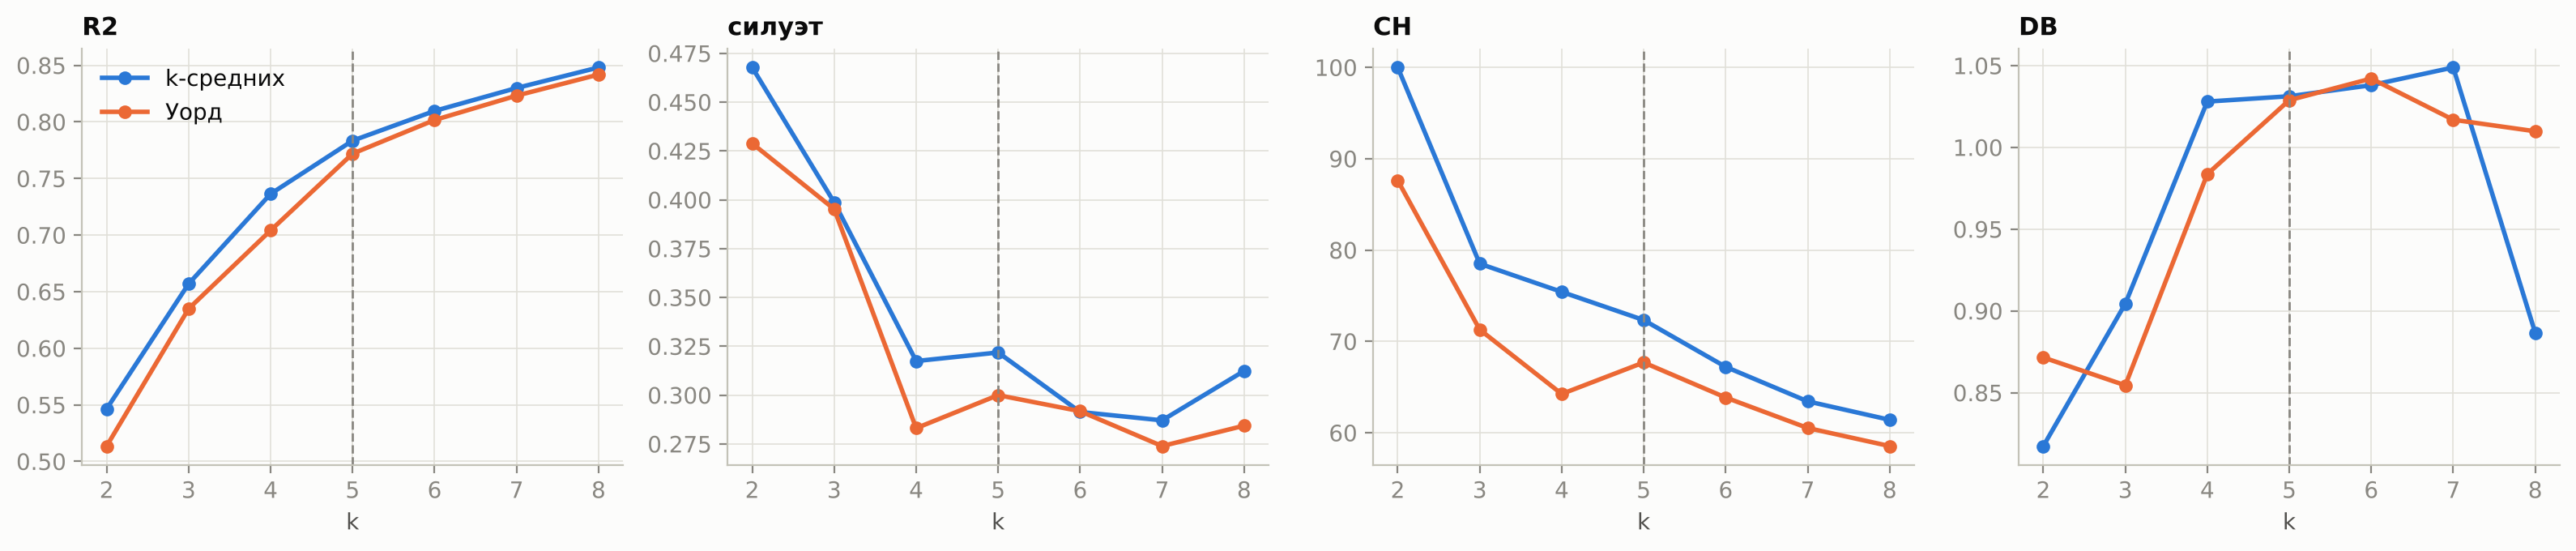

In [3]:
fig, ax = plt.subplots(1, 4, figsize=(16, 3.5))
for a, metric in zip(ax, ["R2", "силуэт", "CH", "DB"]):
    for (name, d), c in zip(ksel.groupby("метод", sort=False), CAT):
        a.plot(d.k, d[metric], marker="o", ms=5, color=c, label=name)
    a.axvline(5, color=MUTED, ls="--", lw=1); a.set_title(metric, loc="left"); a.set_xlabel("k")
ax[0].legend()
plt.tight_layout(); plt.savefig(MAPS / "03_k_selection.png", dpi=150, bbox_inches="tight"); plt.show()

Формальные индексы не дают однозначного оптимума: максимум силуэта при k = 2 — тривиальное деление
«выше/ниже среднего», при k ≥ 3 силуэт k-средних убывает с 0,40 (k = 3) до 0,32 при k = 4 и 5 и почти
не меняется дальше. Поэтому добавлен еще один критерий — **устойчивость разбиения при каждом k**:
к исходным процентам добавляется шум уровня ошибки выборки (σ = 1 и 2 п. п., 100 повторов), разбиение
строится заново и сравнивается с исходным по ARI.

In [4]:
def kmeans_stability(k, sigma, reps=100, seed=SEED):
    """Средний ARI между исходным разбиением k-средних и разбиениями по зашумленным данным."""
    base = KMeans(k, n_init=50, random_state=SEED).fit_predict(Z)
    rng_k = np.random.default_rng(seed + k)
    out = []
    for r in range(reps):
        Zp = StandardScaler().fit_transform(RAWX + rng_k.normal(0, sigma, RAWX.shape))
        out.append(adjusted_rand_score(base, KMeans(k, n_init=20, random_state=SEED + r).fit_predict(Zp)))
    return float(np.mean(out))

kstab = pd.DataFrame([{"k": k, "силуэт": ksel.query("метод == 'k-средних' and k == @k")["силуэт"].iloc[0],
                       "R2": ksel.query("метод == 'k-средних' and k == @k")["R2"].iloc[0],
                       "мин. размер": ksel.query("метод == 'k-средних' and k == @k")["мин. размер"].iloc[0],
                       "ARI σ=1": kmeans_stability(k, 1.0), "ARI σ=2": kmeans_stability(k, 2.0)}
                      for k in range(3, 8)])
kstab.to_csv(RESULTS / "03_k_stability.csv", index=False, encoding="utf-8")
kstab.round(3)

,k,силуэт,R2,мин. размер,ARI σ=1,ARI σ=2
0,3,0.399,0.657,9,0.783,0.628
1,4,0.317,0.736,12,0.846,0.671
2,5,0.322,0.783,7,0.809,0.636
3,6,0.291,0.810,6,0.707,0.529
4,7,0.287,0.830,4,0.630,0.481


In [5]:
# как связаны разбиения при k = 4 и k = 5: выделяется ли при k = 5 новый тип или все перемешивается
lab4 = KMeans(4, n_init=200, random_state=SEED).fit_predict(Z)
lab5 = KMeans(5, n_init=200, random_state=SEED).fit_predict(Z)
print("ARI(k=4, k=5) =", round(adjusted_rand_score(lab4, lab5), 3))
pd.crosstab(pd.Series(lab4, name="k = 4"), pd.Series(lab5, name="k = 5"))

ARI(k=4, k=5) = 0.81


k = 5,0,1,2,3,4
k = 4,,,,,
0,5,0,7,0,0
1,3,32,0,0,0
2,5,0,0,0,15
3,0,0,0,18,0


**Выбор k = 5.**
- По формальным критериям k = 4 и k = 5 близки: силуэт 0,317 и 0,322; k = 4 немного устойчивее к шуму
  (ARI 0,85 против 0,81 при σ = 1 п. п.; 0,67 против 0,64 при σ = 2), k = 5 объясняет больше дисперсии
  ($R^2$ 0,78 против 0,74). При k ≥ 6 устойчивость падает заметно (0,71 и ниже) — это верхняя граница.
  k = 3 дает более высокий силуэт, но объединяет «мобильный» тип со средним уровнем, то есть теряет
  вторую главную компоненту.
- Разбиения при k = 4 и k = 5 вложены (ARI = 0,81): при переходе к k = 5 не перемешивается все, а
  выделяется один новый тип из 13 регионов, собранный из лидеров (5), «мобильных» (5) и среднего уровня (3).
- Решающий довод — **содержательный**. Вторая главная компонента (15,6 % дисперсии) имеет два полюса:
  «мобильная модель» (интернет без ПК) и «компьютерная модель» (много ПК при среднем интернете).
  При k = 4 выделяется только первый полюс, а регионы второго распределяются между лидерами, мобильным
  и средним типами. При k = 5 каждый полюс получает собственный тип («Мобильная модель» и «Развитые»).
- «Локоть» кривой $R^2$: прирост от 4 к 5 кластерам ≈ 5 п. п., дальше ≈ 3 п. п. и меньше; наименьший
  кластер содержит 7 регионов.

*Исправление.* В первой версии ноутбука было написано, что «среди k ≥ 3 силуэт максимален при k = 5».
Это неверно: при k = 3 силуэт выше (0,40). Обоснование заменено на приведенное выше.

Для сравнимости все методы с заданным числом кластеров строятся при k = 5.

In [6]:
K = 5

def order_labels(lab):
    """Перенумеровать кластеры 1..k по возрастанию среднего PC1 (общего уровня цифровизации)."""
    lab = np.asarray(lab)
    means = {c: PC[lab == c, 0].mean() for c in np.unique(lab)}
    rank = {c: i + 1 for i, c in enumerate(sorted(means, key=means.get))}
    return np.array([rank[c] for c in lab])

labels, timing = {}, {}

## 2. Методы
### 2.1. k-средних
$\min_{C_1..C_k}\sum_{c}\sum_{i\in C_c}\lVert z_i-\mu_c\rVert^2$; алгоритм Ллойда, 200 случайных стартов
(k-means++), лучший по инерции. Пространство не учитывается — это базовая признаковая типология.

In [7]:
t = time.time()
labels["k-средних"] = order_labels(KMeans(K, n_init=200, random_state=SEED).fit_predict(Z))
timing["k-средних"] = time.time() - t

### 2.2. Уорд без ограничений
Агломеративная процедура Уорда: на каждом шаге объединяются два кластера с наименьшим приростом
внутрикластерной суммы квадратов. Вторая признаковая типология для сверки с k-средних.

In [8]:
t = time.time()
labels["Уорд"] = order_labels(AgglomerativeClustering(K, linkage="ward").fit_predict(Z))
timing["Уорд"] = time.time() - t

### 2.3. ClustGeo — Уорд на смешанной матрице различий (Chavent и др., 2018)
Две матрицы различий, нормированные на максимум: $D_0$ — евклидовы расстояния в пространстве признаков,
$D_1$ — географические различия (длина кратчайшего пути в графе соседства, то есть «через сколько границ»).
Иерархическая кластеризация Уорда выполняется на

$$D_\alpha=\sqrt{(1-\alpha)D_0^2+\alpha D_1^2},\qquad \alpha\in[0,1].$$

При $\alpha=0$ это обычный Уорд, при $\alpha\to1$ — чисто географическое районирование. Связность кластеров
не гарантируется, но поощряется. Параметр $\alpha$ выбирается по критерию авторов метода: строятся доли
объясненной неоднородности $Q_0(\alpha)$ по признакам и $Q_1(\alpha)$ по географии, нормированные на их
значения при $\alpha=0$ и $\alpha=1$; берется $\alpha$, при котором потеря признаковой однородности
сравнивается с выигрышем пространственной.

In [9]:
D0 = squareform(pdist(Z)); D0 /= D0.max()
D1 = shortest_path(w.sparse, unweighted=True); D1 /= D1.max()

def ward_q(D, lab):
    """Доля объясненной «инерции» для матрицы различий (псевдо-R²): 1 − W/T, W и T — по формуле Уорда."""
    D2 = D ** 2
    T = D2.sum() / (2 * len(lab))
    W = sum(D2[np.ix_(lab == c, lab == c)].sum() / (2 * (lab == c).sum()) for c in np.unique(lab))
    return 1 - W / T

def clustgeo(alpha, k=K):
    Da = np.sqrt((1 - alpha) * D0 ** 2 + alpha * D1 ** 2)
    return fcluster(linkage(squareform(Da, checks=False), "ward"), k, "maxclust")

alphas = np.round(np.arange(0, 1.0001, 0.05), 2)
q = pd.DataFrame([{"alpha": a, "Q0": ward_q(D0, l), "Q1": ward_q(D1, l)} for a in alphas for l in [clustgeo(a)]])
q["Q0n"] = q.Q0 / q.Q0.iloc[0]
q["Q1n"] = q.Q1 / q.Q1.iloc[-1]
alpha_star = float(q.loc[(q.Q0n - q.Q1n).abs().idxmin(), "alpha"])
q.to_csv(RESULTS / "03_clustgeo_alpha.csv", index=False, encoding="utf-8")
print("выбранное α =", alpha_star)
q.round(3).T

выбранное α = 0.25


,0,1,2,3,4,5,6,7,8,9,...,11,12,13,14,15,16,17,18,19,20
alpha,0.000,0.050,0.100,0.150,0.200,0.250,0.300,0.350,0.400,0.450,...,0.550,0.600,0.650,0.700,0.750,0.800,0.850,0.900,0.950,1.000
Q0,0.772,0.777,0.779,0.708,0.697,0.616,0.569,0.569,0.560,0.586,...,0.552,0.488,0.289,0.309,0.289,0.289,0.160,0.160,0.123,0.121
Q1,0.097,0.150,0.138,0.402,0.424,0.616,0.692,0.694,0.697,0.666,...,0.707,0.723,0.793,0.786,0.793,0.793,0.810,0.810,0.812,0.803
Q0n,1.000,1.006,1.009,0.918,0.904,0.798,0.738,0.737,0.726,0.759,...,0.715,0.632,0.374,0.400,0.374,0.374,0.207,0.207,0.159,0.156
Q1n,0.120,0.187,0.172,0.500,0.528,0.768,0.862,0.864,0.868,0.830,...,0.880,0.901,0.988,0.979,0.988,0.988,1.009,1.009,1.012,1.000


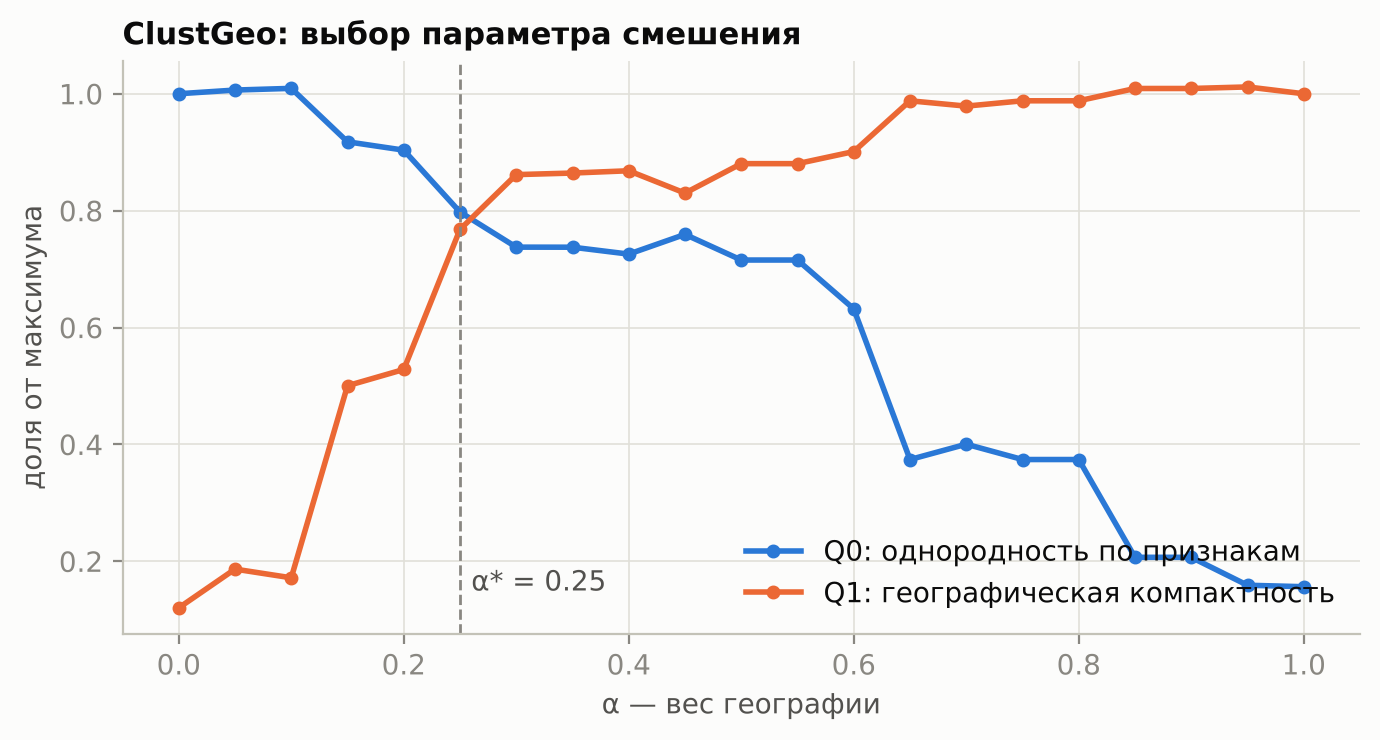

In [10]:
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(q.alpha, q.Q0n, marker="o", ms=4, color=CAT[0], label="Q0: однородность по признакам")
ax.plot(q.alpha, q.Q1n, marker="o", ms=4, color=CAT[1], label="Q1: географическая компактность")
ax.axvline(alpha_star, color=MUTED, ls="--", lw=1); ax.text(alpha_star + 0.01, 0.15, f"α* = {alpha_star}", color=INK2)
ax.set_xlabel("α — вес географии"); ax.set_ylabel("доля от максимума"); ax.legend(loc="lower right")
ax.set_title("ClustGeo: выбор параметра смешения", loc="left")
plt.tight_layout(); plt.savefig(MAPS / "03_clustgeo_alpha.png", dpi=150, bbox_inches="tight"); plt.show()

t = time.time()
labels[f"ClustGeo α={alpha_star}"] = order_labels(clustgeo(alpha_star))
timing[f"ClustGeo α={alpha_star}"] = time.time() - t
CG = f"ClustGeo α={alpha_star}"

### 2.4. Уорд с ограничением смежности
Агломеративная процедура Уорда, в которой на каждом шаге можно объединять только кластеры, соседние в
графе $W$ (`AgglomerativeClustering(connectivity=W)`). Все кластеры связны по построению.

In [11]:
t = time.time()
labels["Уорд со смежностью"] = order_labels(
    AgglomerativeClustering(K, linkage="ward", connectivity=w.sparse).fit_predict(Z))
timing["Уорд со смежностью"] = time.time() - t

### 2.5. SKATER (Assunção и др., 2006)
Ребрам графа соседства приписывается вес $\lVert z_i-z_j\rVert$, строится минимальное остовное дерево,
затем $k-1$ раз удаляется ребро, дающее наибольшее снижение суммы квадратов внутри получающихся частей.
Ограничение: в каждом кластере не менее 3 регионов (`floor=3`), чтобы исключить кластеры-одиночки.

In [12]:
t = time.time()
sk = Skater(gdf, w, ZC, n_clusters=K, floor=3); sk.solve()
labels["SKATER"] = order_labels(sk.labels_)
timing["SKATER"] = time.time() - t

### 2.6. AZP (Openshaw, 1977)
Automatic Zoning Procedure: случайное начальное разбиение на k связных зон, затем локальный поиск —
регионы переносятся между соседними зонами, пока это снижает внутризональную сумму квадратов и не
нарушает связность. Результат зависит от начального разбиения.

In [13]:
t = time.time()
azp = AZP(gdf, w, ZC, n_clusters=K, random_state=SEED); azp.solve()
labels["AZP"] = order_labels(np.asarray(azp.labels_))
timing["AZP"] = time.time() - t

### 2.7. Max-p (Duque и др., 2012; эвристика Wei и др., 2021)
Ищется **наибольшее** число связных кластеров $p$ при ограничении: суммарное население каждого кластера
не меньше порога $L$; затем при найденном $p$ локальным поиском минимизируется неоднородность.
Порог $L$ = 15 млн человек (≈ 10 % населения страны, порядок населения федерального округа): так кластер —
макрорегион, сопоставимый по масштабу с другими методами. Москва (12,6 млн) не может образовать кластер
в одиночку.

In [14]:
gdf["pop"] = gdf.pop_thousands
np.random.seed(SEED)
t = time.time()
mp = MaxPHeuristic(gdf, w, ZC, "pop", 15000, top_n=5, max_iterations_construction=99); mp.solve()
labels["Max-p"] = order_labels(mp.labels_)
timing["Max-p"] = time.time() - t
print({m: len(np.unique(l)) for m, l in labels.items()})

{'k-средних': 5, 'Уорд': 5, 'ClustGeo α=0.25': 5, 'Уорд со смежностью': 5, 'SKATER': 5, 'AZP': 5, 'Max-p': 8}


## 3. Качество разбиений
**В пространстве признаков:** $R^2=1-SS_W/SS_T$ (доля объясненной дисперсии), силуэт, CH, DB.
**В географическом пространстве:**
- *фрагменты* — суммарное число связных частей кластеров в графе соседства (минимум = k: каждый кластер — один массив);
- *доля связей внутри кластеров* — доля пар соседних регионов с одинаковой меткой (1 — полностью районированная карта);
- *путевой силуэт* (path silhouette, Wolf и др., 2021) — силуэт, в котором расстояние до своего кластера
  учитывает только достижимых соседей;
- *компактность* — средний изопериметрический индекс $IPQ=4\pi A/P^2$ объединенных кластеров (1 — круг).

In [15]:
mrows = []
for name, lab in labels.items():
    m = partition_metrics(Z, lab, w, gdf=gdf)
    m["путевой силуэт"] = float(np.mean(esda.path_silhouette(Z, lab, w)))
    m["время, с"] = timing[name]
    mrows.append({"метод": name, **m})
metrics = pd.DataFrame(mrows).set_index("метод")
metrics = metrics.rename(columns={"silhouette": "силуэт", "min_size": "мин. размер", "fragments": "фрагменты",
                                  "within_links": "связи внутри", "IPQ": "компактность"})
metrics.to_csv(RESULTS / "03_partition_metrics.csv", encoding="utf-8")
metrics.round(3)

,k,R2,силуэт,CH,DB,мин. размер,фрагменты,связи внутри,компактность,путевой силуэт,"время, с"
метод,,,,,,,,,,,
k-средних,5,0.783,0.322,72.332,1.031,7,36,0.307,0.023,-0.098,0.127
Уорд,5,0.772,0.300,67.688,1.029,6,35,0.302,0.024,-0.111,0.003
ClustGeo α=0.25,5,0.616,0.016,32.038,2.774,9,16,0.604,0.033,0.153,0.001
Уорд со смежностью,5,0.381,0.109,12.332,2.379,2,5,0.875,0.119,0.075,0.003
SKATER,5,0.322,-0.049,9.515,3.143,3,5,0.839,0.106,0.266,0.111
AZP,5,0.281,-0.071,7.804,3.988,13,5,0.562,0.054,0.053,0.594
Max-p,8,0.385,-0.121,6.874,7.730,5,8,0.510,0.074,0.108,2.488


## 4. Устойчивость
Показатели — результаты **выборочного** обследования, их значения содержат ошибку выборки. Устойчивое
разбиение не должно заметно меняться от небольшого возмущения данных. Опыт: к исходным процентам
добавляется независимый шум $N(0,\sigma^2)$, $\sigma$ = 1 и 2 п. п. (порядок ошибки выборки регионального
обследования: при n ≈ 1000 домохозяйств и доле 80 % стандартная ошибка ≈ 1,3 п. п.), признаки заново
стандартизуются, метод перезапускается (для k-средних и AZP — с новым случайным стартом); сходство с
исходным разбиением — скорректированный индекс Рэнда (ARI: 1 — совпадение, 0 — уровень случайного
совпадения). 100 повторов (для Max-p — 20: он заметно медленнее). В первой версии было 30 повторов
(Max-p — 10), этого мало для оценки худших случаев.

In [16]:
def run(method, Zp, gdfp, seed, ww=None):
    """Перезапуск метода на новых данных Zp (и при необходимости с другой матрицей соседства ww)."""
    ww = w if ww is None else ww
    if method == "k-средних":
        return KMeans(K, n_init=50, random_state=seed).fit_predict(Zp)
    if method == "Уорд":
        return AgglomerativeClustering(K, linkage="ward").fit_predict(Zp)
    if method == CG:
        d0 = squareform(pdist(Zp)); d0 /= d0.max()
        d1 = shortest_path(ww.sparse, unweighted=True); d1 /= d1.max()
        Da = np.sqrt((1 - alpha_star) * d0 ** 2 + alpha_star * d1 ** 2)
        return fcluster(linkage(squareform(Da, checks=False), "ward"), K, "maxclust")
    if method == "Уорд со смежностью":
        return AgglomerativeClustering(K, linkage="ward", connectivity=ww.sparse).fit_predict(Zp)
    cols = [f"_z{i}" for i in range(Zp.shape[1])]
    gp = gdfp.copy(); gp[cols] = Zp
    if method == "SKATER":
        m = Skater(gp, ww, cols, n_clusters=K, floor=3); m.solve(); return m.labels_
    if method == "AZP":
        m = AZP(gp, ww, cols, n_clusters=K, random_state=seed); m.solve(); return np.asarray(m.labels_)
    if method == "Max-p":
        np.random.seed(seed); m = MaxPHeuristic(gp, ww, cols, "pop", 15000, top_n=5, max_iterations_construction=99)
        m.solve(); return m.labels_

N_REP, N_REP_MAXP = 100, 20
rng = np.random.default_rng(SEED)
stab = []
for sigma in (1.0, 2.0):
    for r in range(N_REP):
        Zp = StandardScaler().fit_transform(RAWX + rng.normal(0, sigma, RAWX.shape))
        for method in labels:
            if method == "Max-p" and r >= N_REP_MAXP:
                continue
            stab.append({"σ, п. п.": sigma, "метод": method, "повтор": r,
                         "ARI": adjusted_rand_score(labels[method], run(method, Zp, gdf, SEED + r + 1))})
stab = pd.DataFrame(stab)
stab.to_csv(RESULTS / "03_stability.csv", index=False, encoding="utf-8")
stab_tab = stab.groupby(["метод", "σ, п. п."]).ARI.agg(["mean", "std", "min"]).unstack().round(3)
stab_tab

mean           std           min       
σ, п. п.              1.0    2.0    1.0    2.0    1.0    2.0
метод                                                       
AZP                 0.355  0.358  0.111  0.112  0.182  0.158
ClustGeo α=0.25     0.751  0.615  0.141  0.143  0.340  0.273
Max-p               0.588  0.526  0.086  0.054  0.427  0.406
SKATER              0.819  0.677  0.224  0.211  0.158  0.221
k-средних           0.835  0.645  0.101  0.099  0.547  0.453
Уорд                0.674  0.502  0.130  0.114  0.376  0.268
Уорд со смежностью  0.721  0.618  0.311  0.332  0.044  0.039

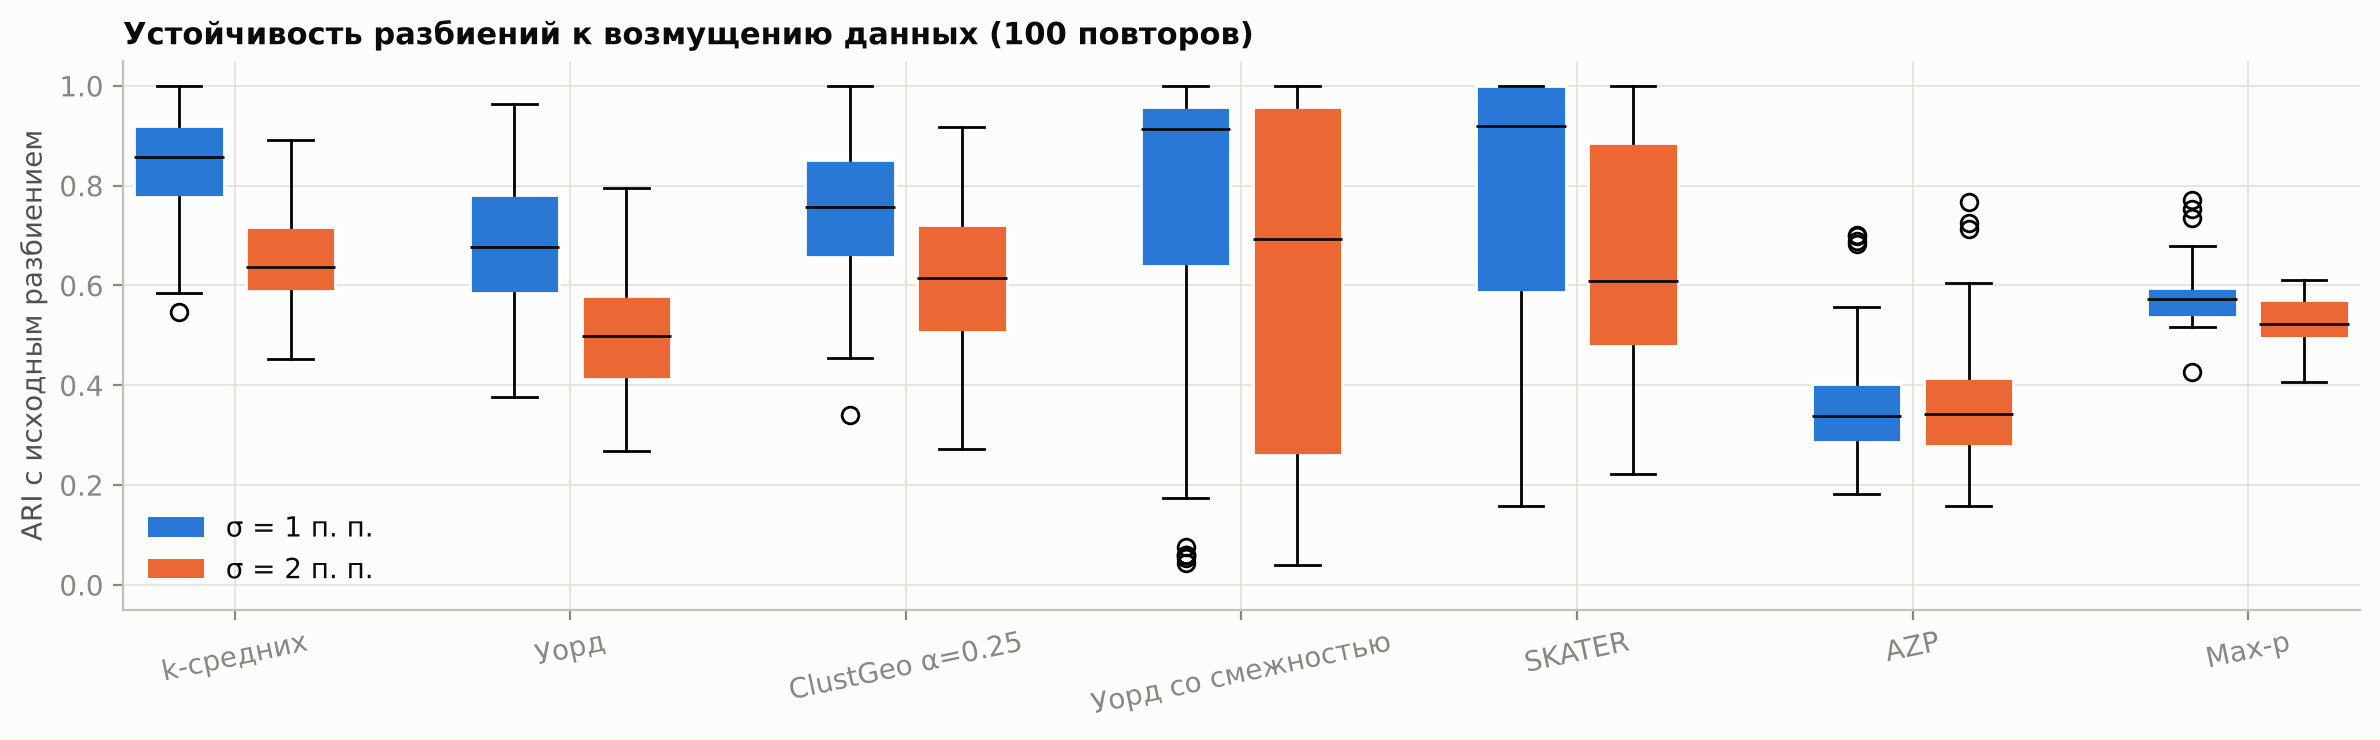

In [17]:
fig, ax = plt.subplots(figsize=(12, 3.8))
meths = list(labels)
for j, sigma in enumerate((1.0, 2.0)):
    d = [stab[(stab["метод"] == m) & (stab["σ, п. п."] == sigma)].ARI for m in meths]
    bp = ax.boxplot(d, positions=np.arange(len(meths)) * 3 + j, widths=0.8, patch_artist=True,
                    medianprops=dict(color="#0b0b0b"))
    for b in bp["boxes"]:
        b.set_facecolor(CAT[j]); b.set_edgecolor("#ffffff")
ax.set_xticks(np.arange(len(meths)) * 3 + 0.5, meths, rotation=12)
ax.set_ylabel("ARI с исходным разбиением"); ax.set_ylim(-0.05, 1.05)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(facecolor=CAT[0], label="σ = 1 п. п."), Patch(facecolor=CAT[1], label="σ = 2 п. п.")], loc="lower left")
ax.set_title(f"Устойчивость разбиений к возмущению данных ({N_REP} повторов)", loc="left")
plt.tight_layout(); plt.savefig(MAPS / "03_stability.png", dpi=150, bbox_inches="tight"); plt.show()

### Чувствительность к набору признаков и к схеме соседства
Каждый метод перезапускается при одном измененном решении, результат сравнивается с основным разбиением (ARI):
1. **3 признака без ШПД.** Доступ в интернет и ШПД почти дублируют друг друга (r = 0,96). Этот вариант
   проверяет, не определяется ли разбиение двойным весом «доступа».
2. **2 главные компоненты** (94 % дисперсии). Проверка слабая: расстояния между регионами при этом почти
   не меняются, поэтому высокий ARI ожидаем заранее. Оставлена для сопоставимости с первой версией.
3. **KNN, k = 6 (симметризованная) вместо Queen** — только для методов, использующих соседство.
   Для признаковых методов результат по построению не зависит от матрицы соседства.

In [18]:
F3 = [f for f in FEATURES if f != "broadband"]
Z3 = StandardScaler().fit_transform(gdf[F3])
PC2 = np.c_[PC, np.zeros((len(PC), 2))]   # 2 ГК + нулевые столбцы — те же расстояния, та же размерность
pts = gdf.geometry.representative_point()
knn = KNN.from_array(np.c_[pts.x, pts.y], k=6)
w_knn = WeightsW({i: sorted(set(knn.neighbors[i]) | {j for j in range(knn.n) if i in knn.neighbors[j]})
                  for i in range(knn.n)}, silence_warnings=True)
SPATIAL = [m for m in labels if m not in ("k-средних", "Уорд")]
sens = pd.DataFrame({
    "3 признака (без ШПД)": {m: adjusted_rand_score(labels[m], run(m, Z3, gdf, SEED)) for m in labels},
    "2 ГК": {m: adjusted_rand_score(labels[m], run(m, PC2, gdf, SEED)) for m in labels},
    "W = KNN-6": {m: adjusted_rand_score(labels[m], run(m, Z, gdf, SEED, ww=w_knn)) if m in SPATIAL else np.nan
                  for m in labels},
})
sens.to_csv(RESULTS / "03_sensitivity.csv", encoding="utf-8")
sens.round(3)

,3 признака (без ШПД),2 ГК,W = KNN-6
k-средних,0.598,0.979,NaN
Уорд,0.591,0.726,NaN
ClustGeo α=0.25,0.882,0.547,0.416
Уорд со смежностью,0.727,0.957,0.170
SKATER,0.694,0.416,0.258
AZP,0.592,0.722,0.160
Max-p,0.643,0.615,0.365


**Итоги проверки чувствительности.**
- **Набор признаков существенно влияет на результат.** Без ШПД разбиение k-средних совпадает с основным лишь
  на ARI ≈ 0,6. Набор из четырех признаков оставлен основным по двум причинам. Во-первых, все четыре показателя
  входят в задание группы. Во-вторых, разбиения по четырем признакам устойчивее к ошибке выборки: в варианте
  команды с тремя признаками (k = 4) средний ARI при σ = 1 п. п. был 0,71 против 0,84 здесь. Два почти
  совпадающих показателя доступа частично усредняют выборочный шум друг друга. Оговорка: в опыте шум
  у них независимый, а в реальном обследовании ошибки, скорее всего, связаны, так что выигрыш может быть завышен.
- **Замена на 2 главные компоненты** почти не меняет k-средних (ARI 0,98), но, как сказано выше, это слабая
  проверка.
- **Методы, использующие соседство, сильно зависят от матрицы весов:** при переходе от Queen к KNN-6 ARI
  падает до 0,16–0,42. Их разбиения — следствие не только данных, но и выбранной схемы соседства. Признаковые
  методы от нее не зависят по построению.

## 5. Согласованность методов

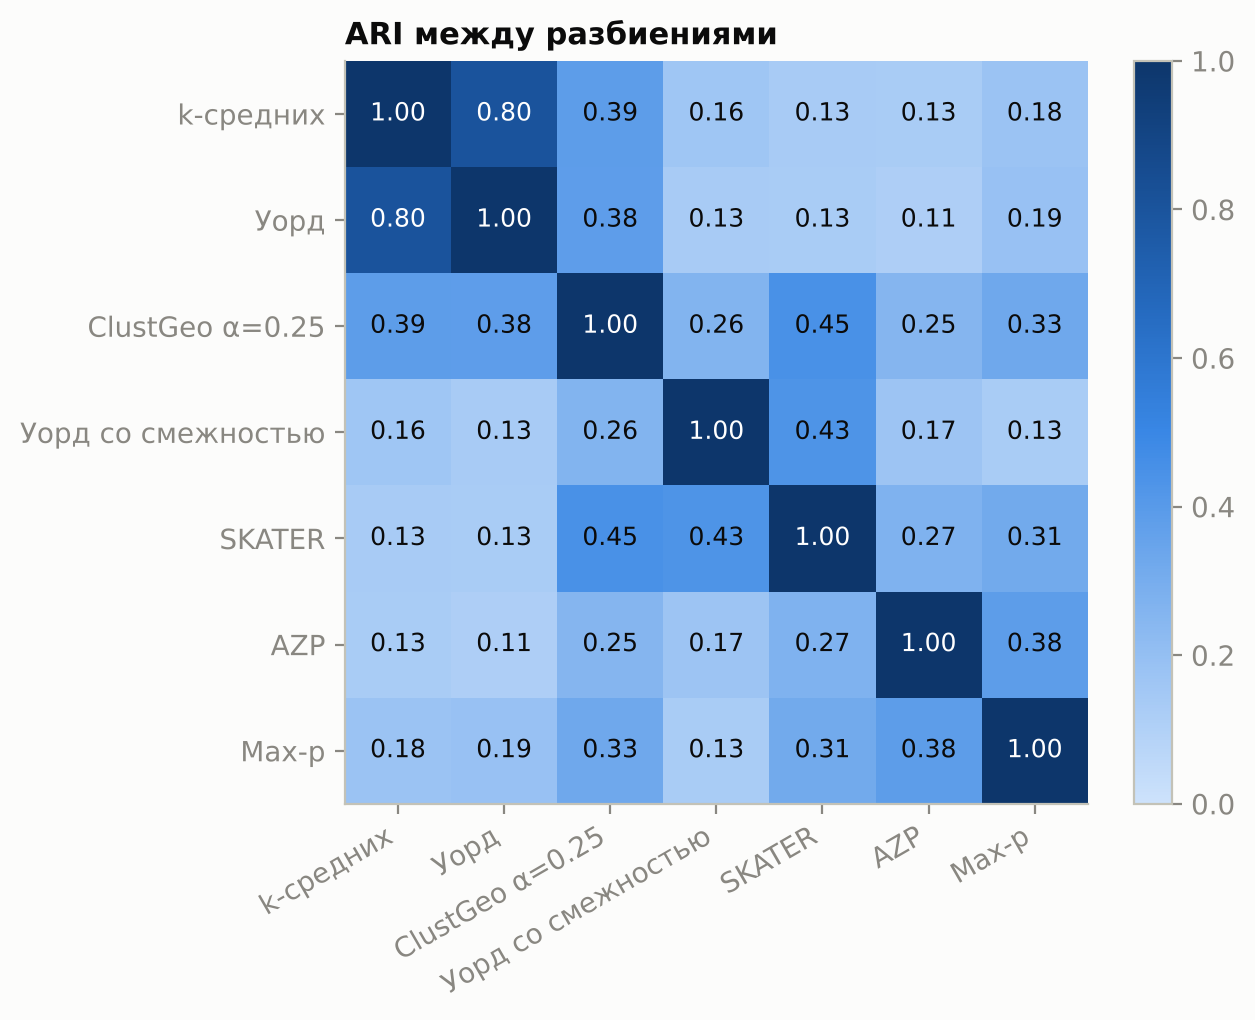

In [19]:
A = pd.DataFrame([[adjusted_rand_score(labels[a], labels[b]) for b in labels] for a in labels], index=labels, columns=labels)
A.to_csv(RESULTS / "03_ari_between_methods.csv", encoding="utf-8")
fig, ax = plt.subplots(figsize=(6.4, 5.2))
im = ax.imshow(A, cmap=SEQ, vmin=0, vmax=1); ax.grid(False)
ax.set_xticks(range(len(A)), A.columns, rotation=30, ha="right"); ax.set_yticks(range(len(A)), A.index)
for i in range(len(A)):
    for j in range(len(A)):
        ax.text(j, i, f"{A.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9,
                color="#ffffff" if A.iloc[i, j] > 0.6 else "#0b0b0b")
plt.colorbar(im, ax=ax, fraction=0.046); ax.set_title("ARI между разбиениями", loc="left")
plt.tight_layout(); plt.savefig(MAPS / "03_ari_matrix.png", dpi=150, bbox_inches="tight"); plt.show()

## 6. Карты всех разбиений

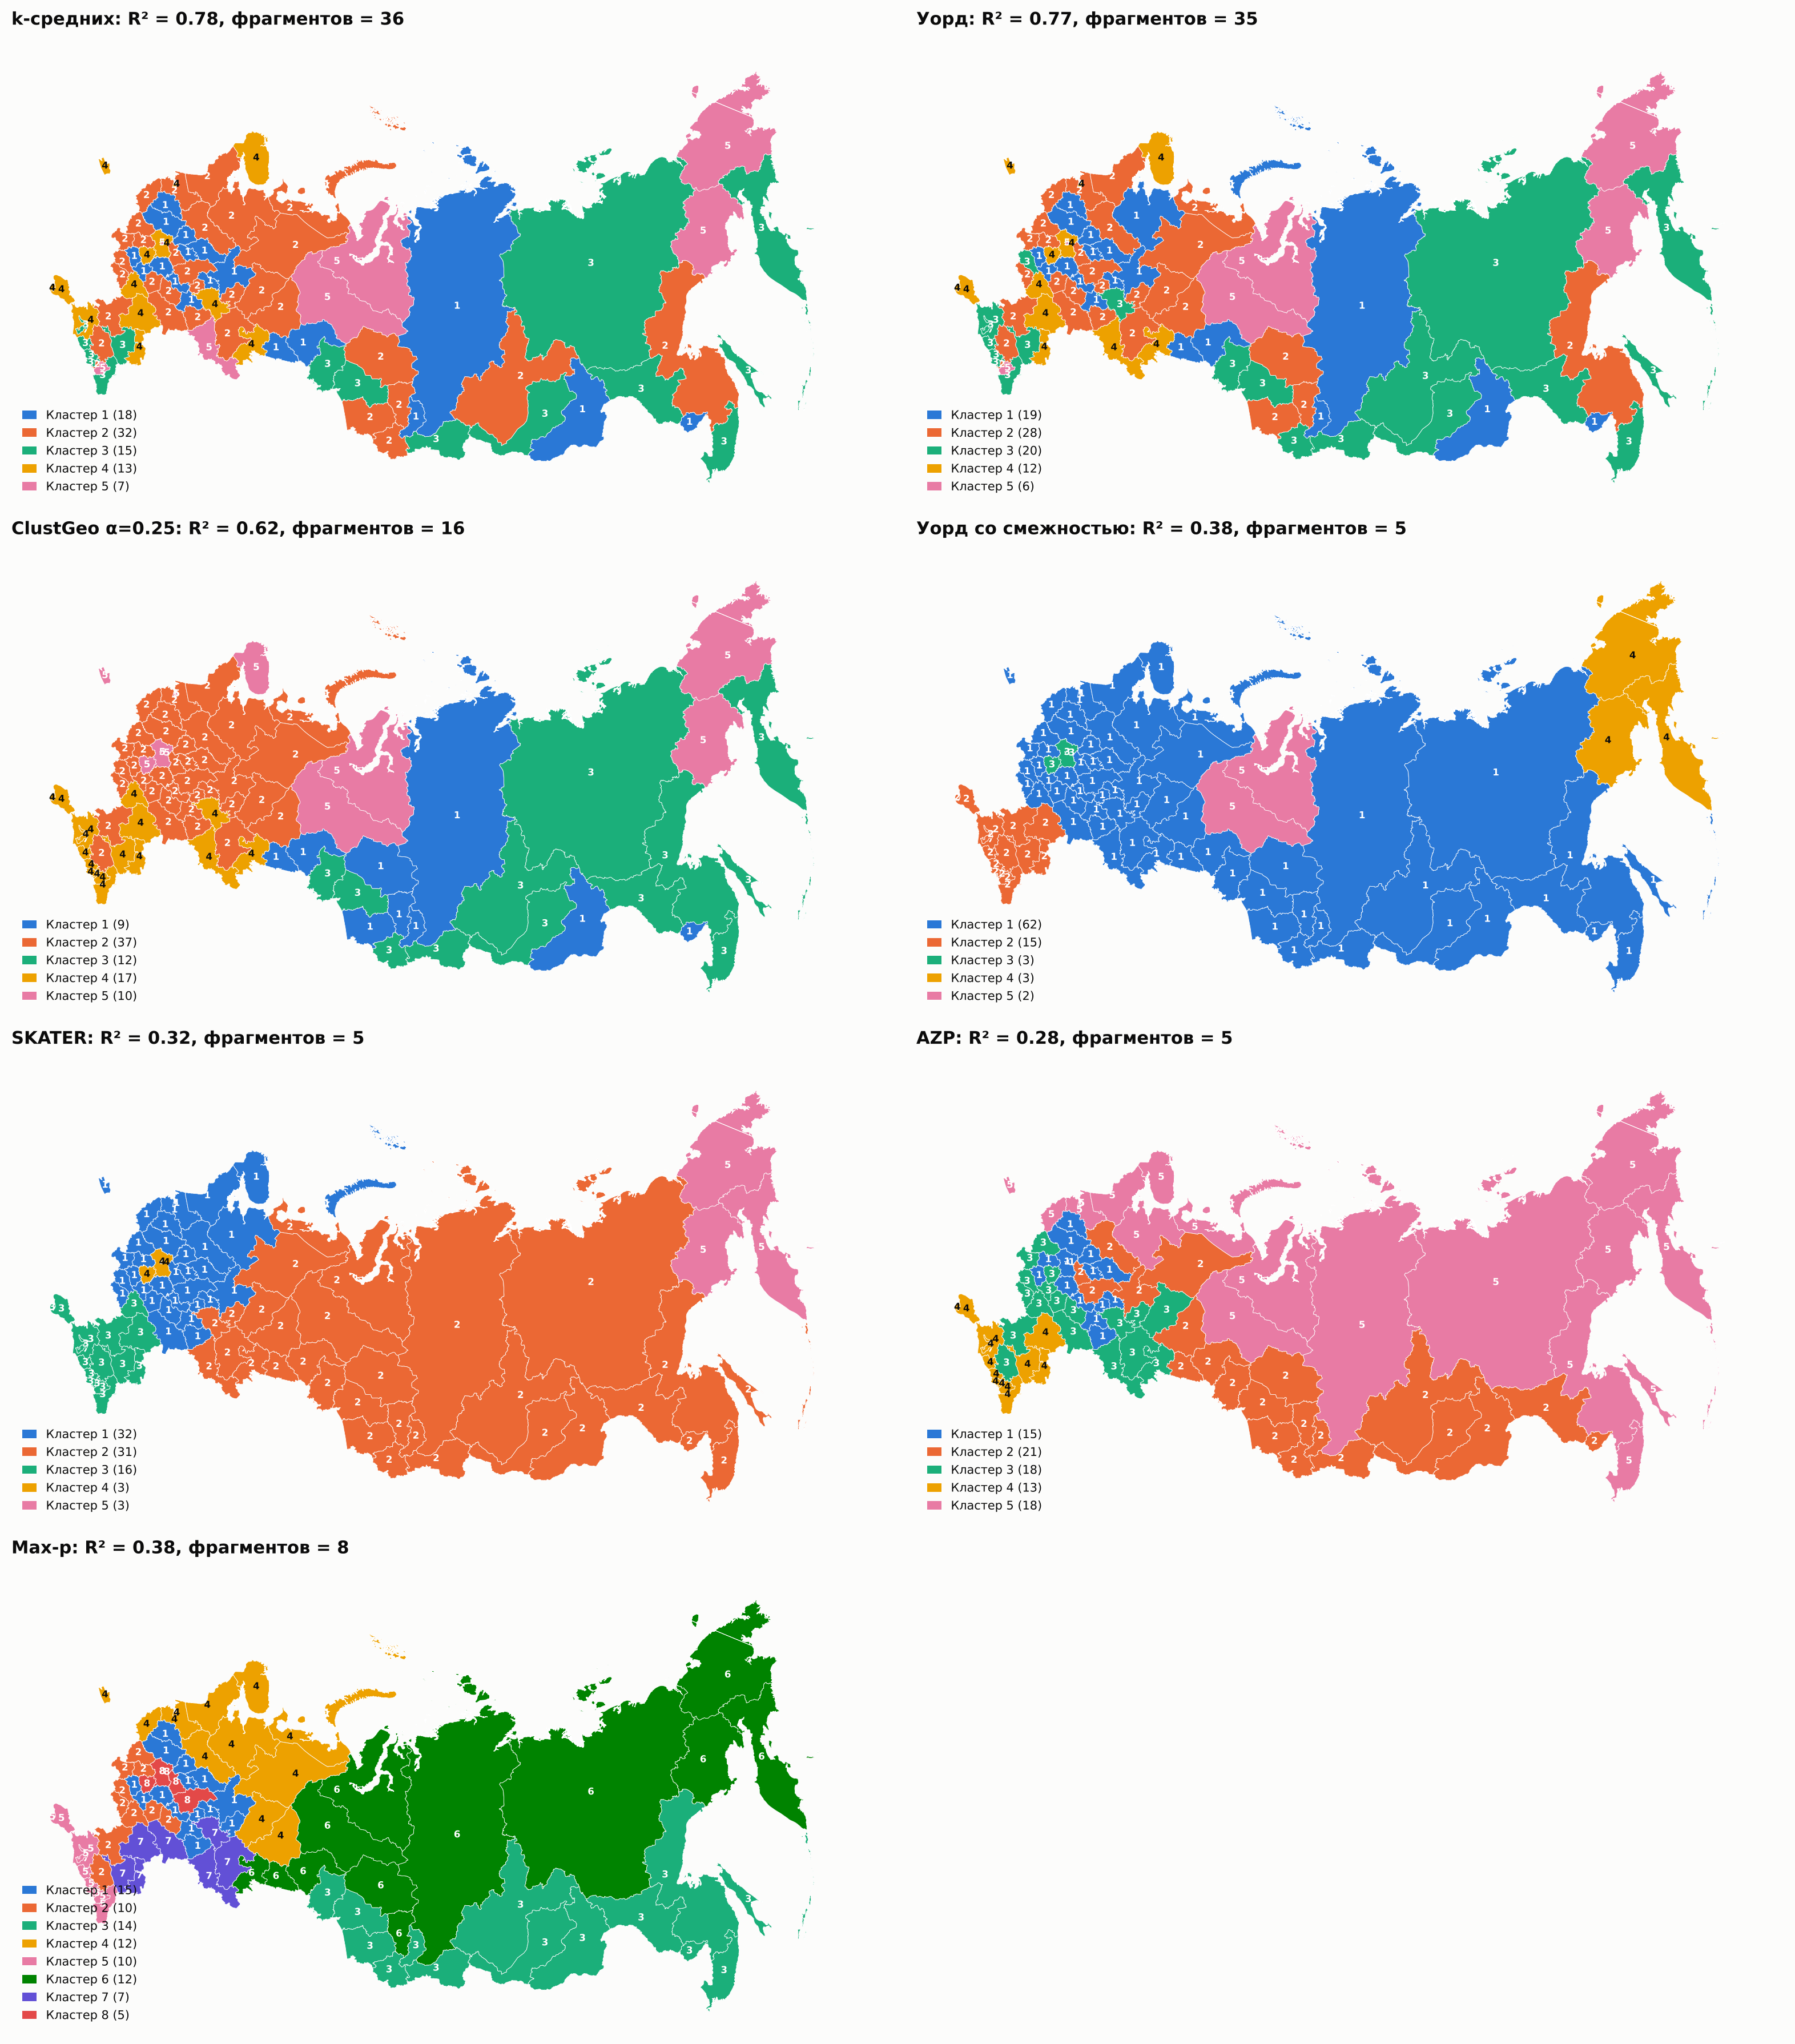

In [20]:
fig, axes = plt.subplots(4, 2, figsize=(16, 18))
for ax, (name, lab) in zip(axes.ravel(), labels.items()):
    r = metrics.loc[name]
    cluster_map(ax, gdf, lab, title=f"{name}: R² = {r.R2:.2f}, фрагментов = {int(r['фрагменты'])}")
axes.ravel()[-1].set_axis_off()
plt.tight_layout(); plt.savefig(MAPS / "03_all_partitions.png", dpi=150, bbox_inches="tight"); plt.show()

In [21]:
out = gdf[["okato", "name"]].copy()
for name, lab in labels.items():
    out[name] = lab
out.to_csv(RESULTS / "03_labels.csv", index=False, encoding="utf-8")